In [7]:
import pandas as pd
import itertools
from pathlib import Path

# Set up paths
DATA_DIR = Path("../data")
BOT9_DIR = DATA_DIR / "bot9_grid_search"
BOT8_PATH = DATA_DIR / "bot8_chronological_results.csv"

TAU_VALS = [0.2, 0.6, 1.0]
S1_VALS = [0.3, 0.5, 0.7]
S2_VALS = [0.2, 0.5, 1.0]

# 177 games total (59 games per third)
START_IDX = 1689
P1_END = START_IDX + 58
P2_END = P1_END + 59
P3_END = P2_END + 59  # Game 1865 (28/07/26)

def get_period_averages(file_path):
    if not file_path.exists():
        return None
    
    df = pd.read_csv(file_path)
    
    # Isolate the exact 177-game window
    df = df[(df['game_num'] >= START_IDX) & (df['game_num'] <= P3_END)]
    if df.empty or len(df) < 177:
        return None
        
    t1 = df[(df['game_num'] >= START_IDX) & (df['game_num'] <= P1_END)]['guess_count'].mean()
    t2 = df[(df['game_num'] > P1_END) & (df['game_num'] <= P2_END)]['guess_count'].mean()
    t3 = df[(df['game_num'] > P2_END) & (df['game_num'] <= P3_END)]['guess_count'].mean()
    overall = df['guess_count'].mean()
    
    return {"Third 1": t1, "Third 2": t2, "Third 3": t3, "Overall": overall}

# Process Bot 8 Baseline
bot8_stats = get_period_averages(BOT8_PATH)

print("================================================================================")
print("BOT 8 BASELINE (Games 1689 to 1865)")
print("================================================================================")
if bot8_stats:
    print(f"Third 1 (Games {START_IDX}-{P1_END}):  {bot8_stats['Third 1']:.4f}")
    print(f"Third 2 (Games {P1_END+1}-{P2_END}):  {bot8_stats['Third 2']:.4f}")
    print(f"Third 3 (Games {P2_END+1}-{P3_END}):  {bot8_stats['Third 3']:.4f}")
    print(f"Overall (177 games):        {bot8_stats['Overall']:.4f}\n")
else:
    print("Bot 8 data not found or incomplete.\n")

# Process Bot 9 Grid Search
results = []
for tau, s1, s2 in itertools.product(TAU_VALS, S1_VALS, S2_VALS):
    file_path = BOT9_DIR / f"bot9_tau{tau:.1f}_s1_{s1:.1f}_s2_{s2:.1f}.csv"
    stats = get_period_averages(file_path)
    if stats:
        stats.update({'tau': tau, 's1': s1, 's2': s2})
        results.append(stats)

df_results = pd.DataFrame(results)

print("================================================================================")
print("BOT 9 CONFIGURATIONS (Sorted by Overall Average)")
print("================================================================================")
if not df_results.empty:
    # Reorder columns for readability
    df_results = df_results[['tau', 's1', 's2', 'Third 1', 'Third 2', 'Third 3', 'Overall']]
    df_results = df_results.sort_values('Overall').reset_index(drop=True)
    
    # Format and print the dataframe
    print(df_results.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
else:
    print("No complete Bot 9 data found for this range.")

BOT 8 BASELINE (Games 1689 to 1865)
Third 1 (Games 1689-1747):  3.1695
Third 2 (Games 1748-1806):  3.2373
Third 3 (Games 1807-1865):  3.0000
Overall (177 games):        3.1356

BOT 9 CONFIGURATIONS (Sorted by Overall Average)
   tau     s1     s2  Third 1  Third 2  Third 3  Overall
1.0000 0.3000 0.2000   3.1186   3.2034   2.9831   3.1017
1.0000 0.3000 0.5000   3.1356   3.2373   2.9831   3.1186
1.0000 0.3000 1.0000   3.1186   3.2373   3.0000   3.1186
1.0000 0.5000 0.2000   3.1525   3.2203   3.0000   3.1243
1.0000 0.7000 1.0000   3.1525   3.2203   3.0000   3.1243
1.0000 0.5000 1.0000   3.1525   3.2373   3.0000   3.1299
1.0000 0.7000 0.5000   3.1525   3.2373   3.0000   3.1299
0.6000 0.7000 1.0000   3.1695   3.2712   2.9661   3.1356
0.6000 0.7000 0.5000   3.1525   3.2881   2.9661   3.1356
1.0000 0.7000 0.2000   3.1695   3.2373   3.0000   3.1356
1.0000 0.5000 0.5000   3.1695   3.2373   3.0000   3.1356
0.6000 0.3000 1.0000   3.1525   3.2881   2.9831   3.1412
0.6000 0.3000 0.2000   3.1525   3

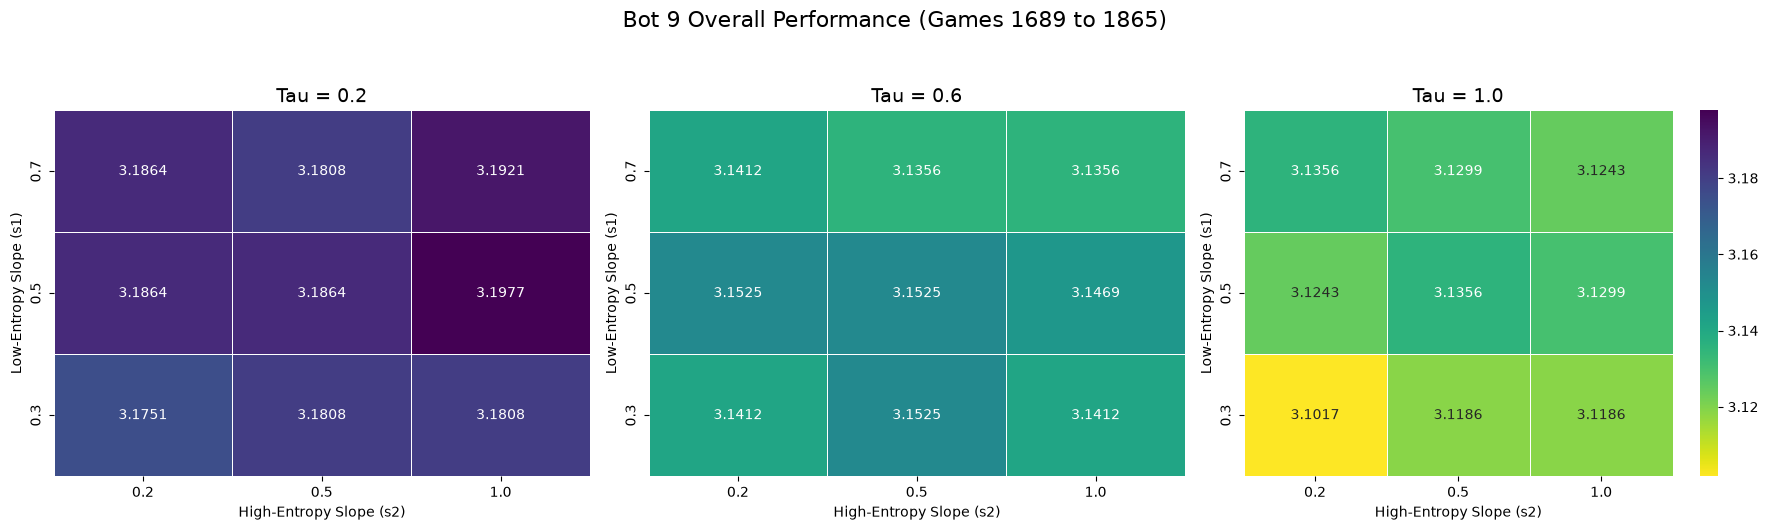

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

if not df_results.empty:
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle("Bot 9 Overall Performance (Games 1689 to 1865)", fontsize=16, y=1.05)
    
    vmin = df_results['Overall'].min()
    vmax = df_results['Overall'].max()
    
    for i, tau in enumerate([0.2, 0.6, 1.0]):
        ax = axes[i]
        df_tau = df_results[df_results['tau'] == tau]
        
        if df_tau.empty:
            ax.set_title(f"Tau = {tau} (No Data)")
            continue
            
        pivot_df = df_tau.pivot(index='s1', columns='s2', values='Overall')
        
        sns.heatmap(
            pivot_df, 
            annot=True, 
            fmt=".4f", 
            cmap="viridis_r", 
            vmin=vmin, 
            vmax=vmax,
            cbar=(i == 2), 
            ax=ax,
            linewidths=.5
        )
        
        ax.set_title(f"Tau = {tau}", fontsize=14)
        ax.set_xlabel("High-Entropy Slope (s2)")
        ax.set_ylabel("Low-Entropy Slope (s1)")
        ax.invert_yaxis()
        
    plt.tight_layout()
    plt.show()
else:
    print("No data available to plot.")

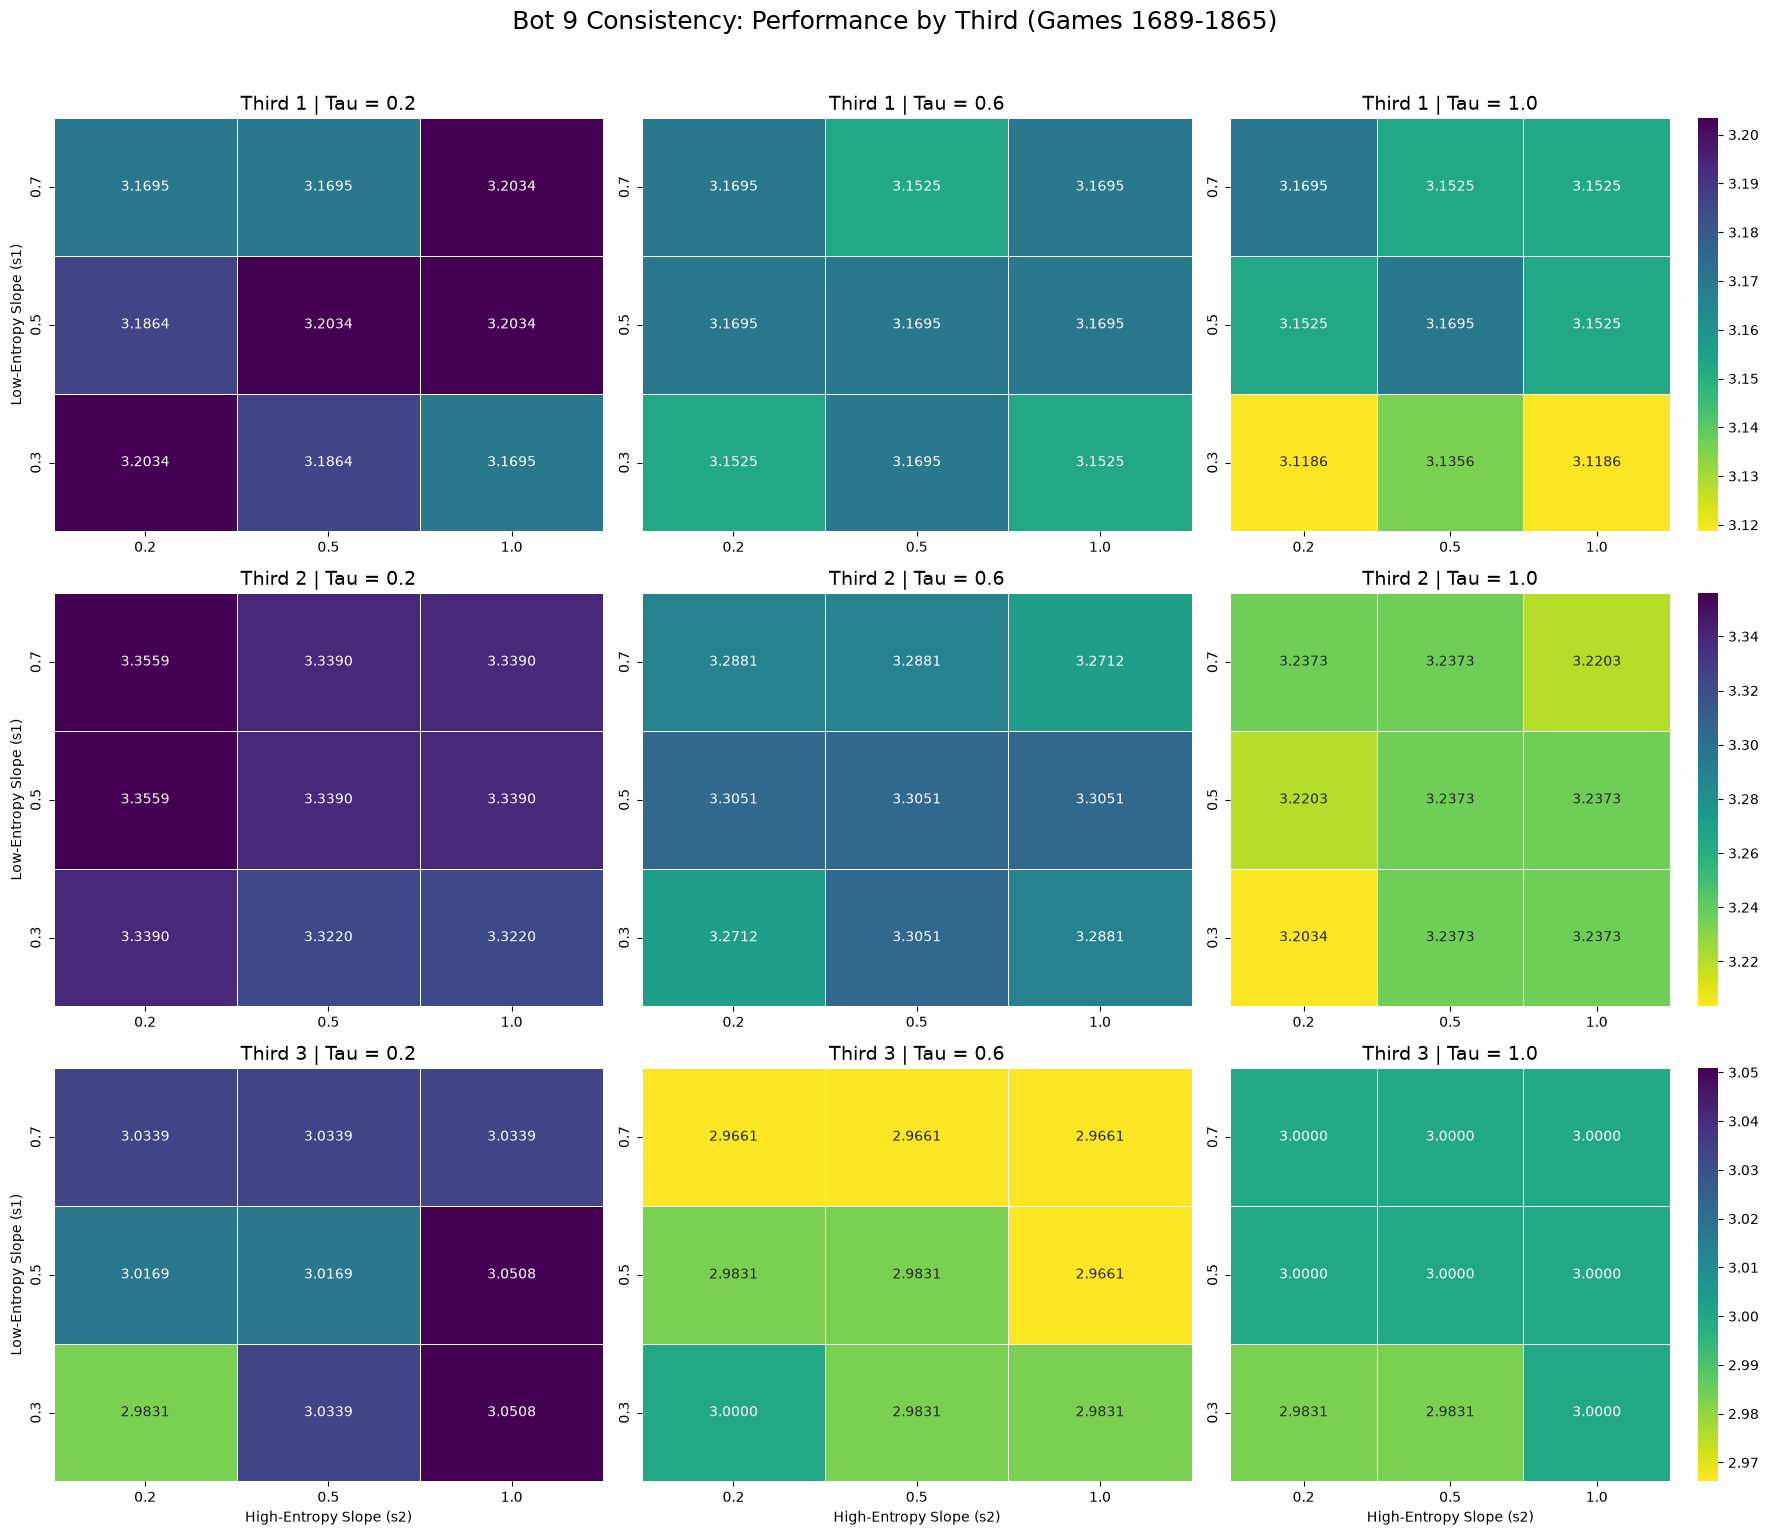

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

if not df_results.empty:
    periods = ['Third 1', 'Third 2', 'Third 3']
    
    # Create a 3x3 figure: Rows = Periods, Columns = Tau values
    fig, axes = plt.subplots(3, 3, figsize=(18, 15))
    fig.suptitle("Bot 9 Consistency: Performance by Third (Games 1689-1865)", fontsize=18, y=1.02)
    
    for row_idx, period in enumerate(periods):
        # Set vmin/vmax per period to keep the color scale relative to that specific batch's difficulty
        vmin = df_results[period].min()
        vmax = df_results[period].max()
        
        for col_idx, tau in enumerate(TAU_VALS):
            ax = axes[row_idx, col_idx]
            df_tau = df_results[df_results['tau'] == tau]
            
            if df_tau.empty:
                ax.set_title(f"{period} | Tau = {tau} (No Data)")
                continue
                
            # Pivot the data for the heatmap
            pivot_df = df_tau.pivot(index='s1', columns='s2', values=period)
            
            sns.heatmap(
                pivot_df, 
                annot=True, 
                fmt=".4f", 
                cmap="viridis_r", 
                vmin=vmin, 
                vmax=vmax,
                cbar=(col_idx == 2), # Show colorbar only on the far right column
                ax=ax,
                linewidths=.5
            )
            
            ax.set_title(f"{period} | Tau = {tau}", fontsize=14)
            
            # Clean up axes labels so they don't clutter the inside of the grid
            ax.set_xlabel("High-Entropy Slope (s2)" if row_idx == 2 else "")
            ax.set_ylabel("Low-Entropy Slope (s1)" if col_idx == 0 else "")
            ax.invert_yaxis() # Put higher slopes at the top
            
    plt.tight_layout()
    plt.show()
else:
    print("No data available to plot.")

Fair comparison enforced: Evaluating 173 identical games across all configurations.


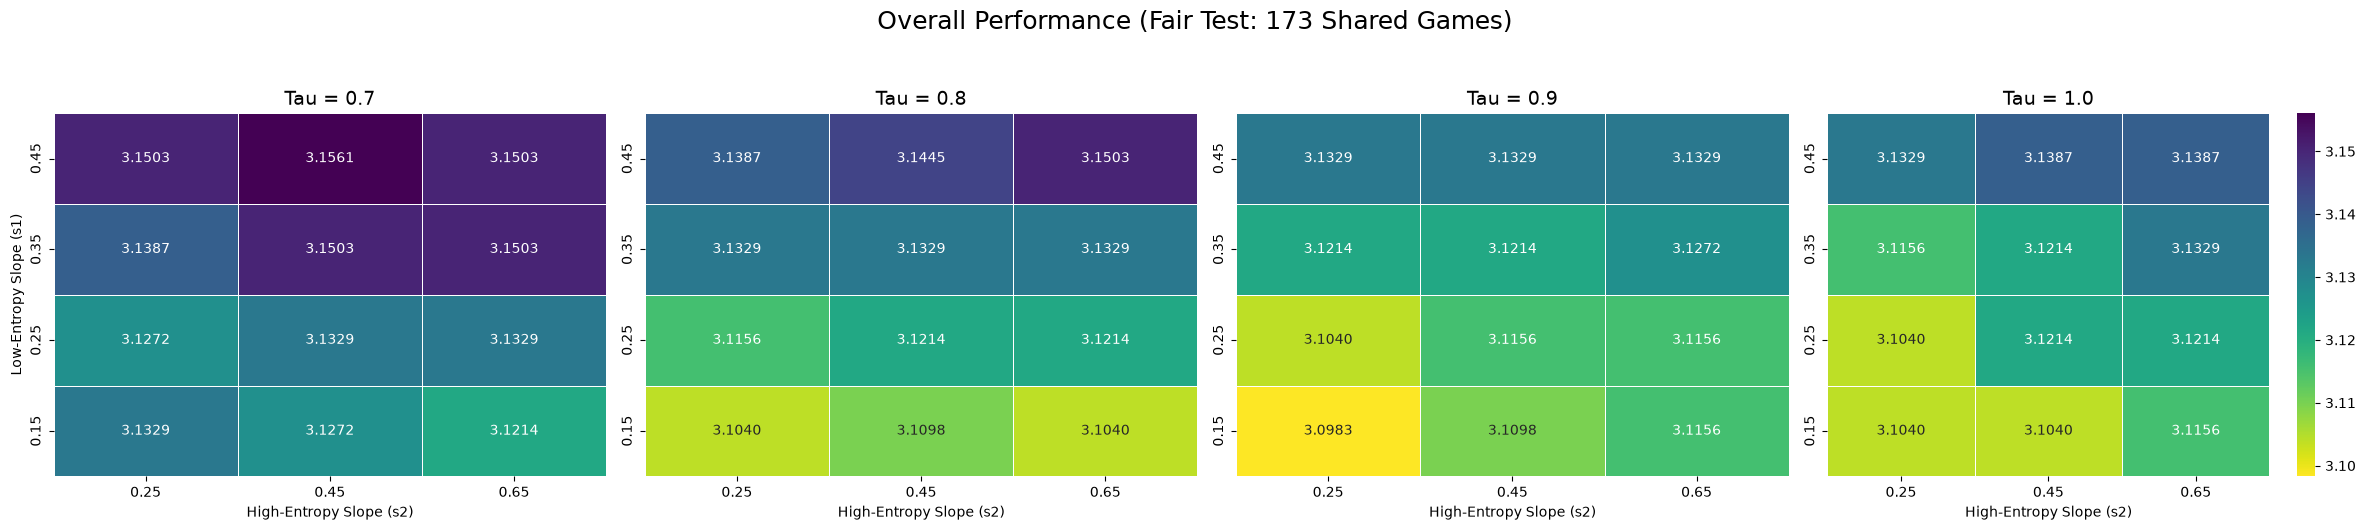

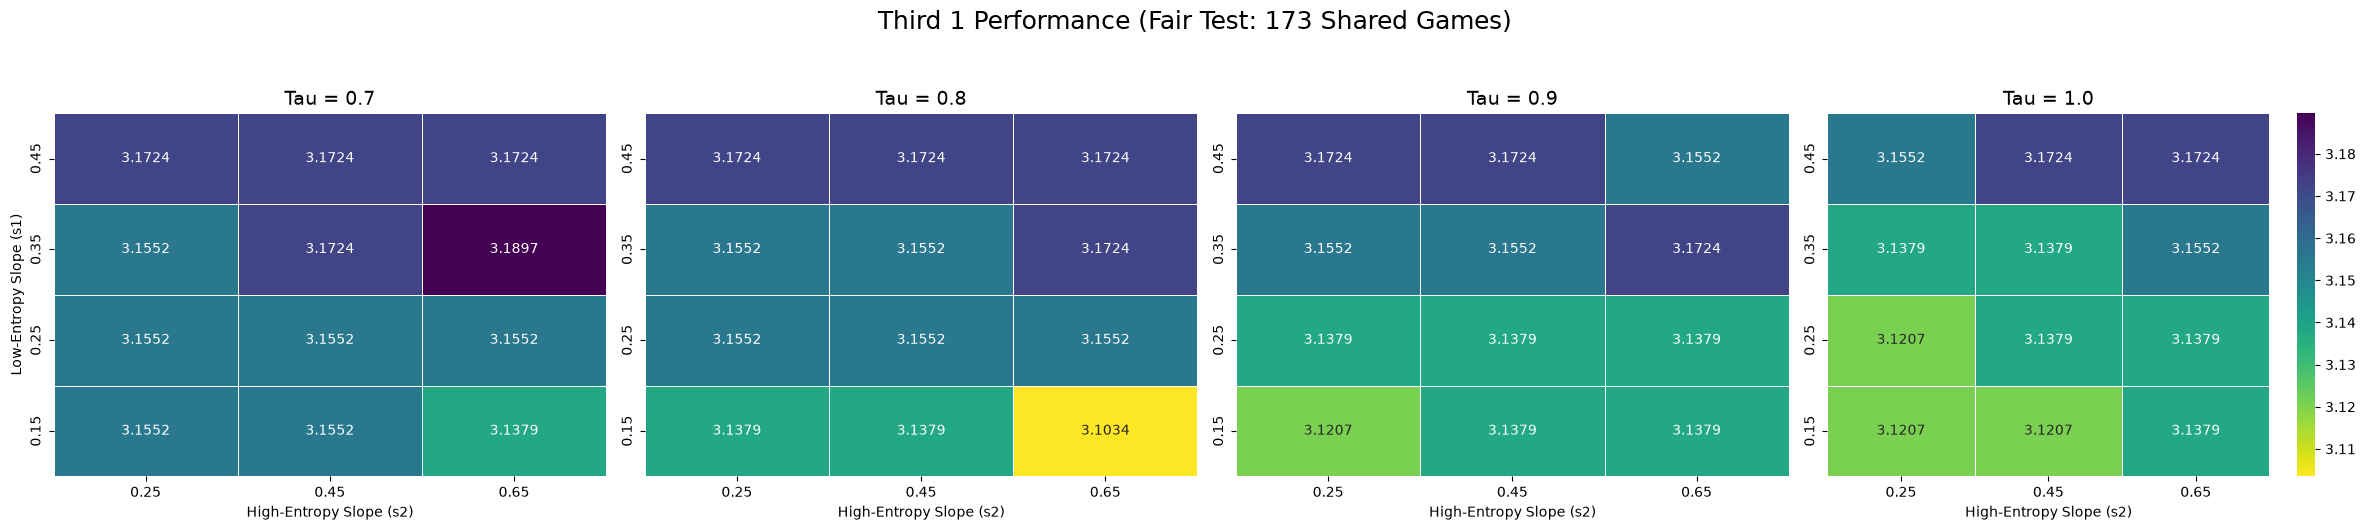

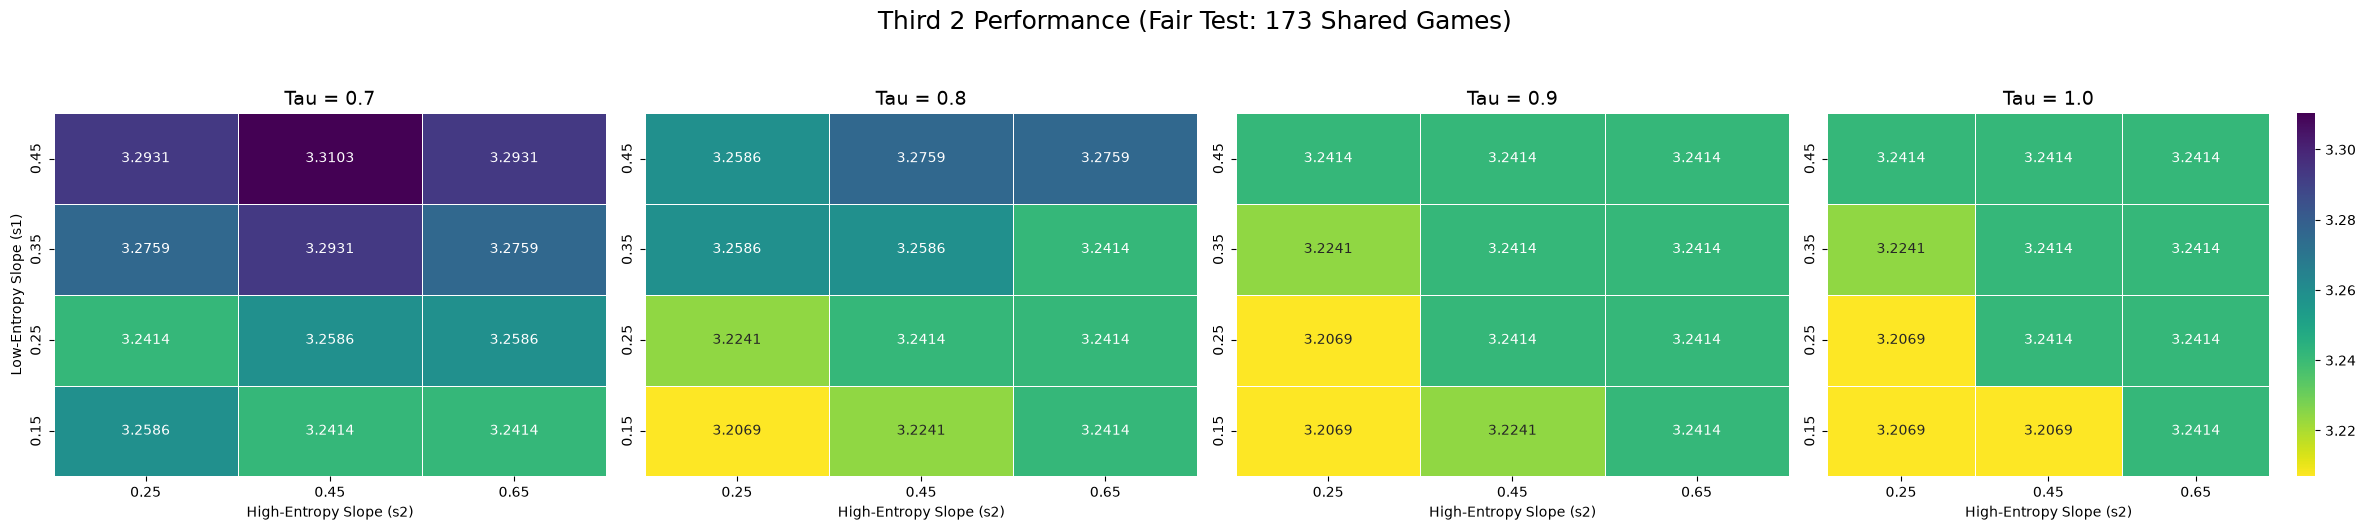

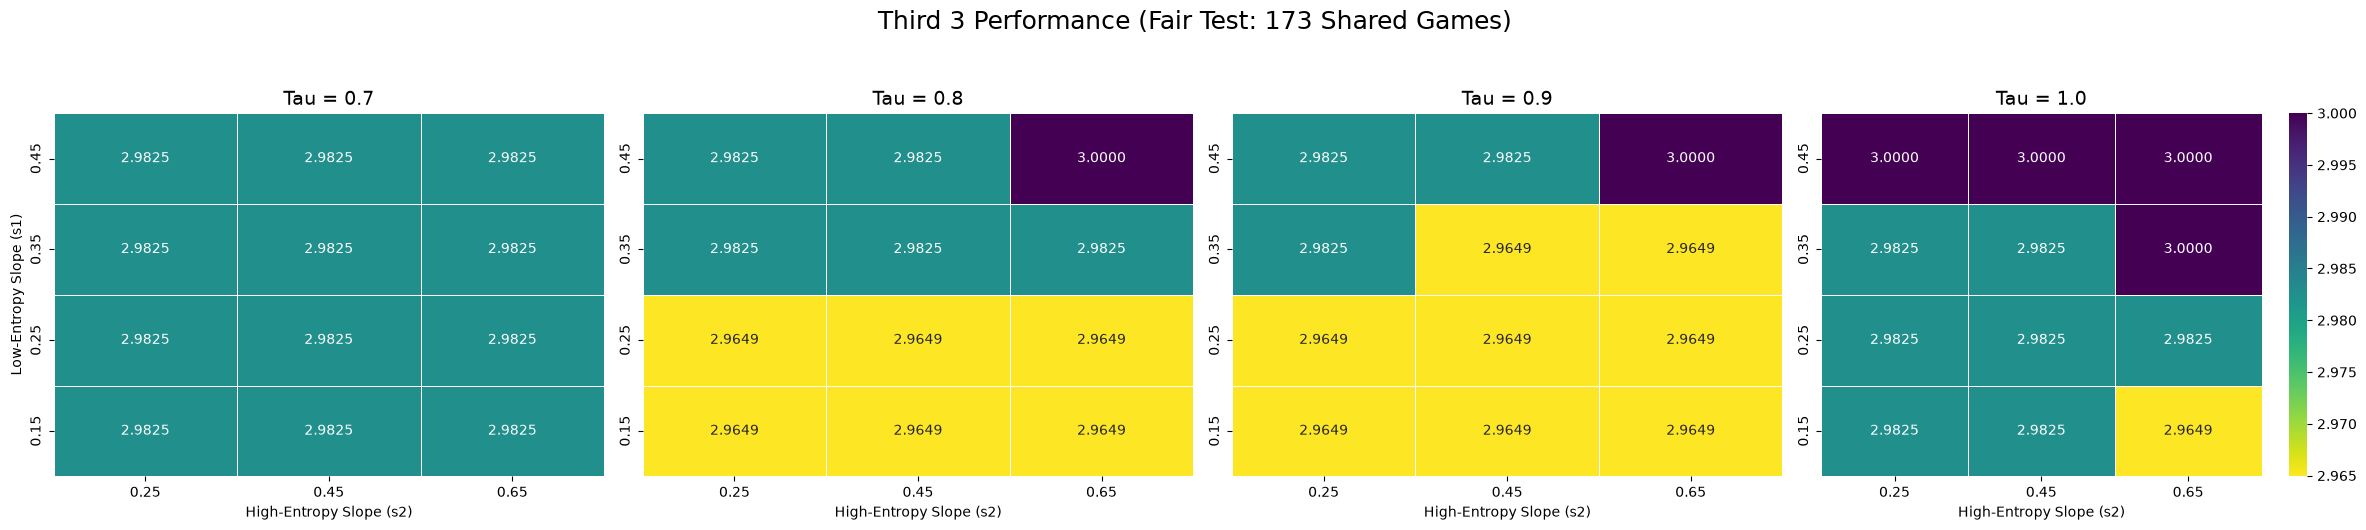

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import re

# Set up paths for the v2 grid search
DATA_DIR = Path("../data")
BOT9_DIR = DATA_DIR / "bot9_grid_search_v2"

# Game index splits
START_IDX = 1689
P1_END = START_IDX + 58
P2_END = P1_END + 59
P3_END = P2_END + 59

# 1. Load all dataframes and filter to the target date range
all_configs = []
for file_path in BOT9_DIR.glob("bot9_tau*_s1_*_s2_*.csv"):
    match = re.search(r"tau([\d\.]+)_s1_([\d\.]+)_s2_([\d\.]+)\.csv", file_path.name)
    if not match:
        continue
        
    tau, s1, s2 = map(float, match.groups())
    df = pd.read_csv(file_path)
    df_target = df[(df['game_num'] >= START_IDX) & (df['game_num'] <= P3_END)].copy()
    
    if not df_target.empty:
        all_configs.append({
            'tau': tau, 's1': s1, 's2': s2,
            'df': df_target,
            'games': set(df_target['game_num'])
        })

if not all_configs:
    print("No Bot 9 v2 data found for this range.")
else:
    # 2. Find the exact intersection of games across ALL configs for a 100% fair test
    common_games = all_configs[0]['games']
    for config in all_configs[1:]:
        common_games = common_games.intersection(config['games'])
        
    print(f"Fair comparison enforced: Evaluating {len(common_games)} identical games across all configurations.")

    # 3. Calculate averages using ONLY the intersected common games
    results = []
    for config in all_configs:
        df_fair = config['df'][config['df']['game_num'].isin(common_games)]
        
        t1 = df_fair[(df_fair['game_num'] >= START_IDX) & (df_fair['game_num'] <= P1_END)]['guess_count'].mean()
        t2 = df_fair[(df_fair['game_num'] > P1_END) & (df_fair['game_num'] <= P2_END)]['guess_count'].mean()
        t3 = df_fair[(df_fair['game_num'] > P2_END) & (df_fair['game_num'] <= P3_END)]['guess_count'].mean()
        overall = df_fair['guess_count'].mean()
        
        results.append({
            'tau': config['tau'], 's1': config['s1'], 's2': config['s2'],
            'Third 1': t1, 'Third 2': t2, 'Third 3': t3, 'Overall': overall
        })

    df_results = pd.DataFrame(results)
    
    # 4. Plot the gapless heatmaps
    df_results = df_results.sort_values(by=['tau', 's1', 's2'])
    unique_taus = sorted(df_results['tau'].unique())
    periods = ['Overall', 'Third 1', 'Third 2', 'Third 3']
    
    for period in periods:
        fig, axes = plt.subplots(1, len(unique_taus), figsize=(6 * len(unique_taus), 5))
        if len(unique_taus) == 1:
            axes = [axes]
            
        fig.suptitle(f"{period} Performance (Fair Test: {len(common_games)} Shared Games)", fontsize=18, y=1.05)
        
        vmin = df_results[period].min()
        vmax = df_results[period].max()
        
        for i, tau in enumerate(unique_taus):
            ax = axes[i]
            df_tau = df_results[df_results['tau'] == tau]
            
            pivot_df = df_tau.pivot(index='s1', columns='s2', values=period)
            
            sns.heatmap(
                pivot_df, 
                annot=True, 
                fmt=".4f", 
                cmap="viridis_r", 
                vmin=vmin, 
                vmax=vmax,
                cbar=(i == len(unique_taus) - 1),
                ax=ax,
                linewidths=.5
            )
            
            ax.set_title(f"Tau = {tau}", fontsize=14)
            ax.set_xlabel("High-Entropy Slope (s2)")
            ax.set_ylabel("Low-Entropy Slope (s1)" if i == 0 else "")
            ax.invert_yaxis()
            
        plt.tight_layout()
        plt.show()

Fair comparison enforced: Evaluating 176 identical games across all configurations.


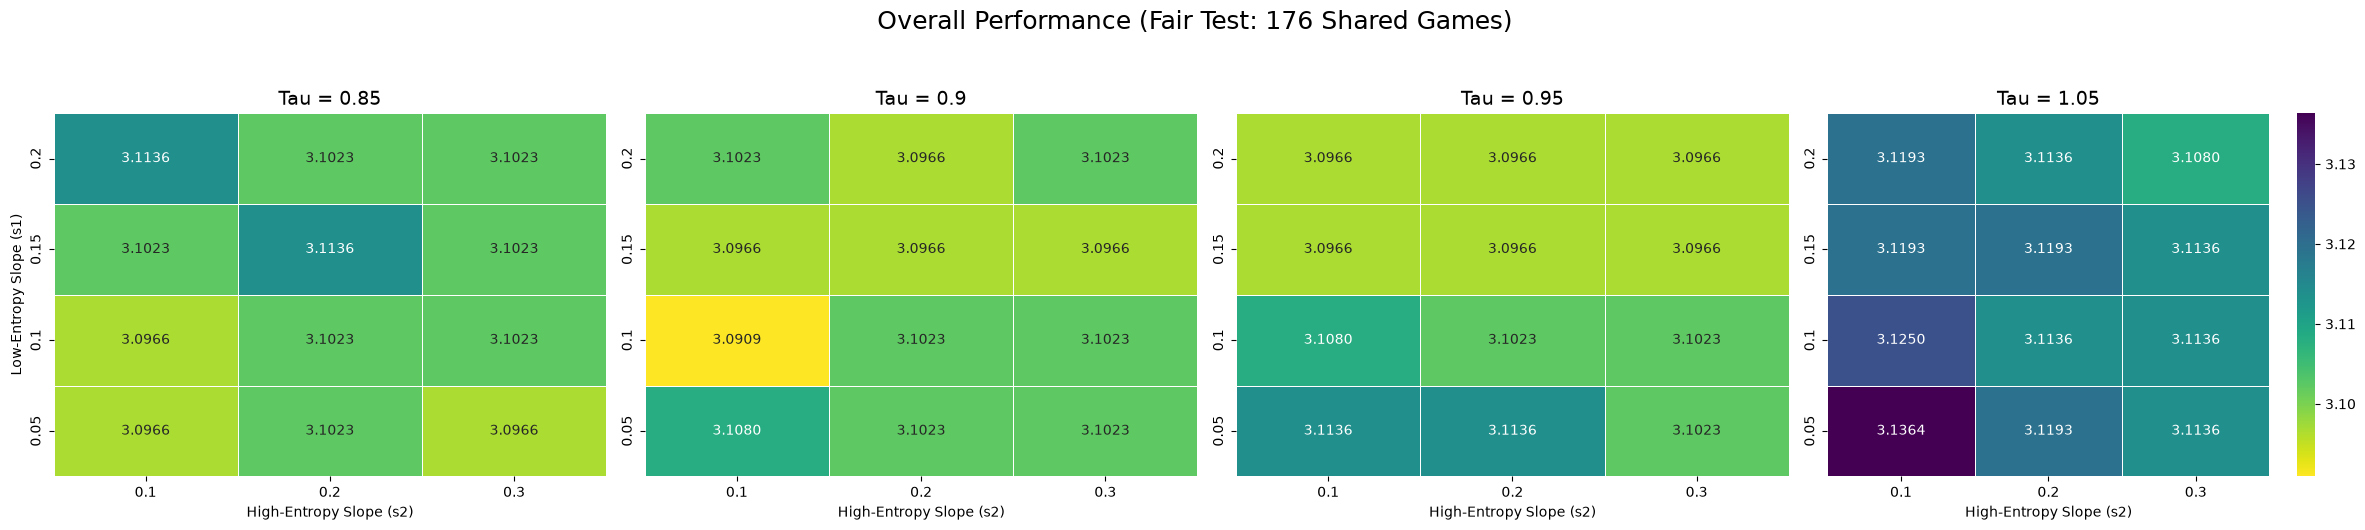

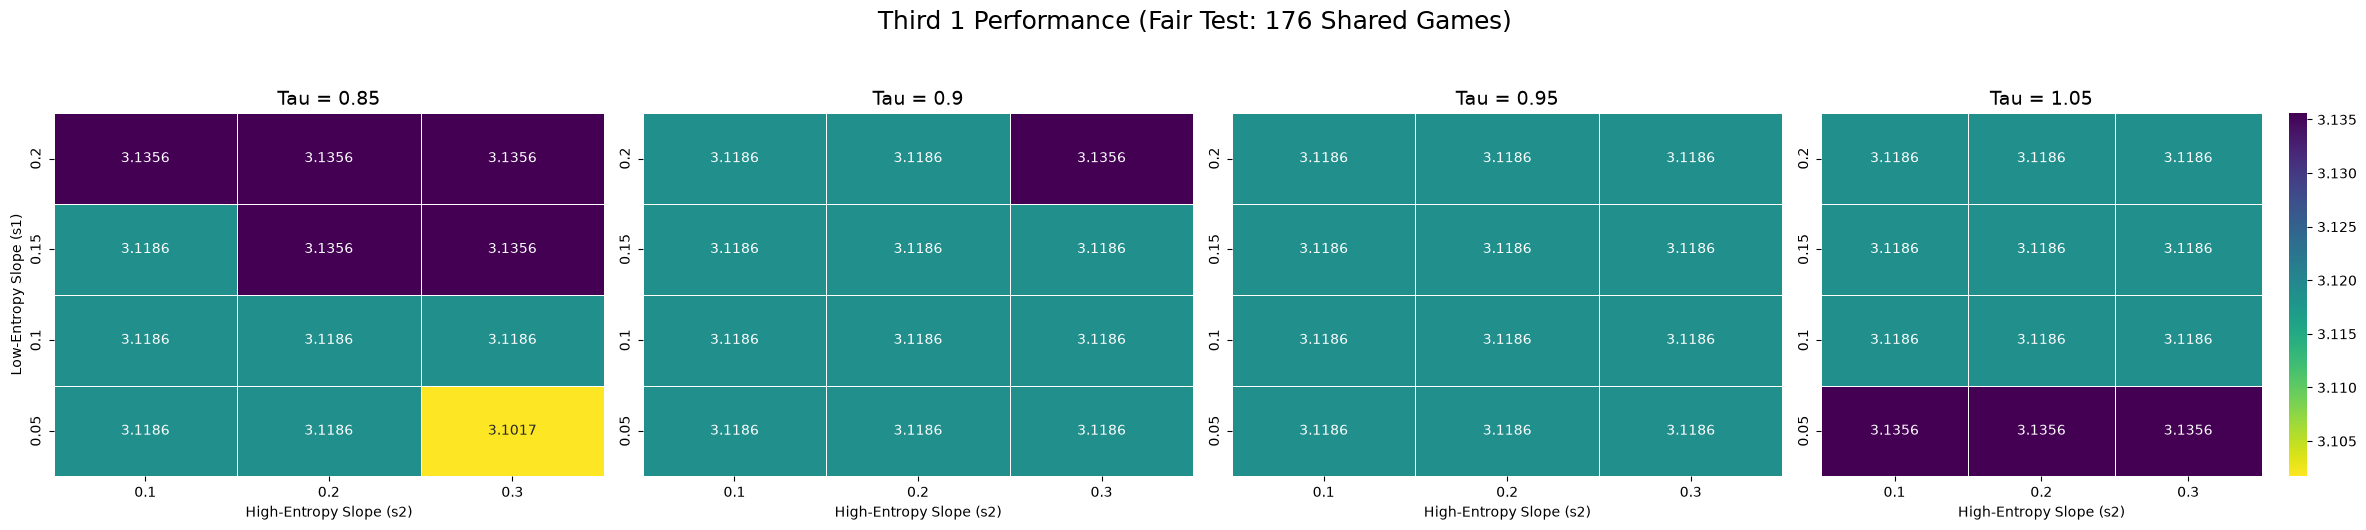

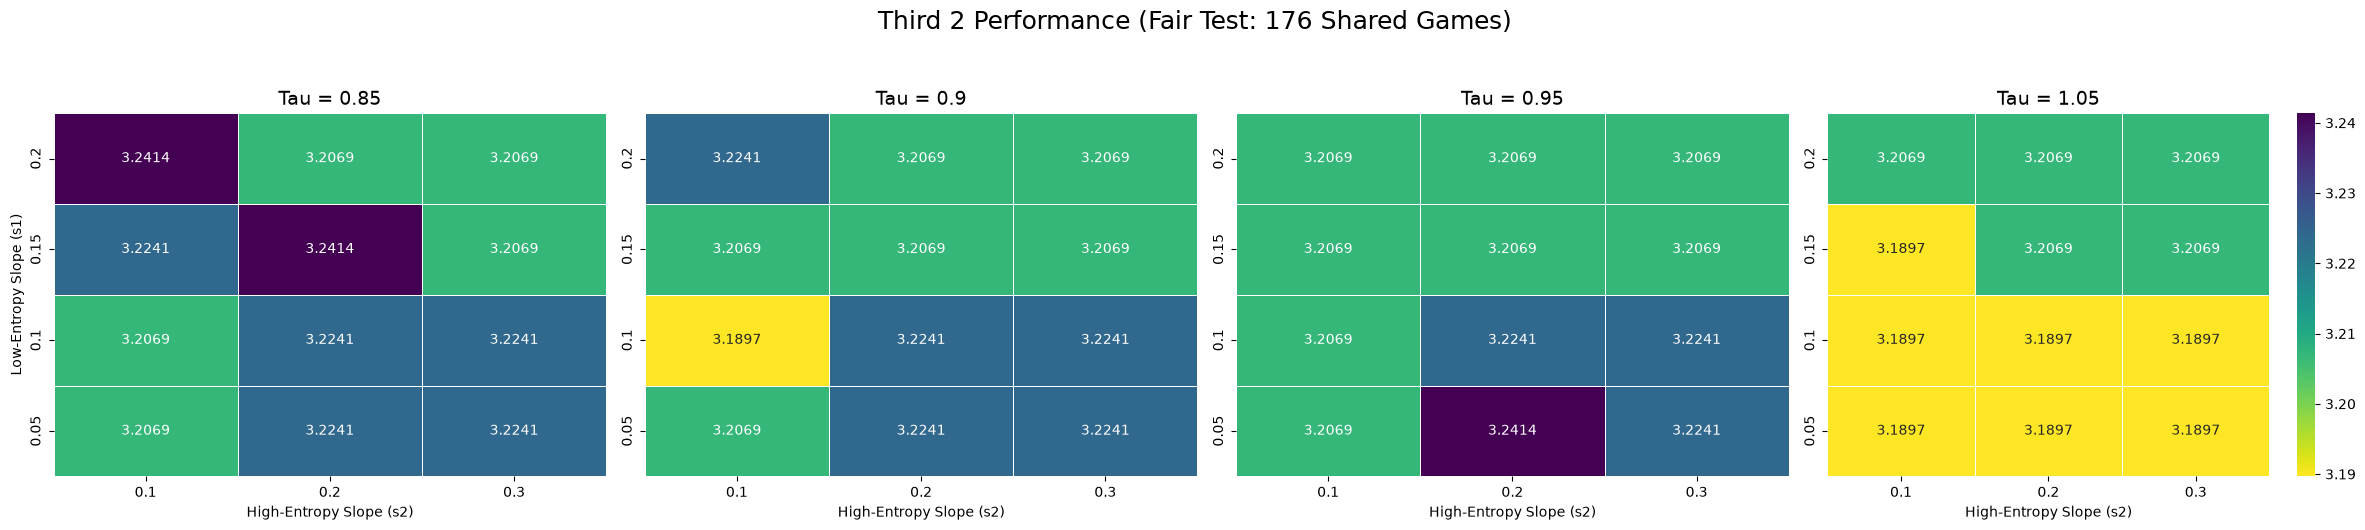

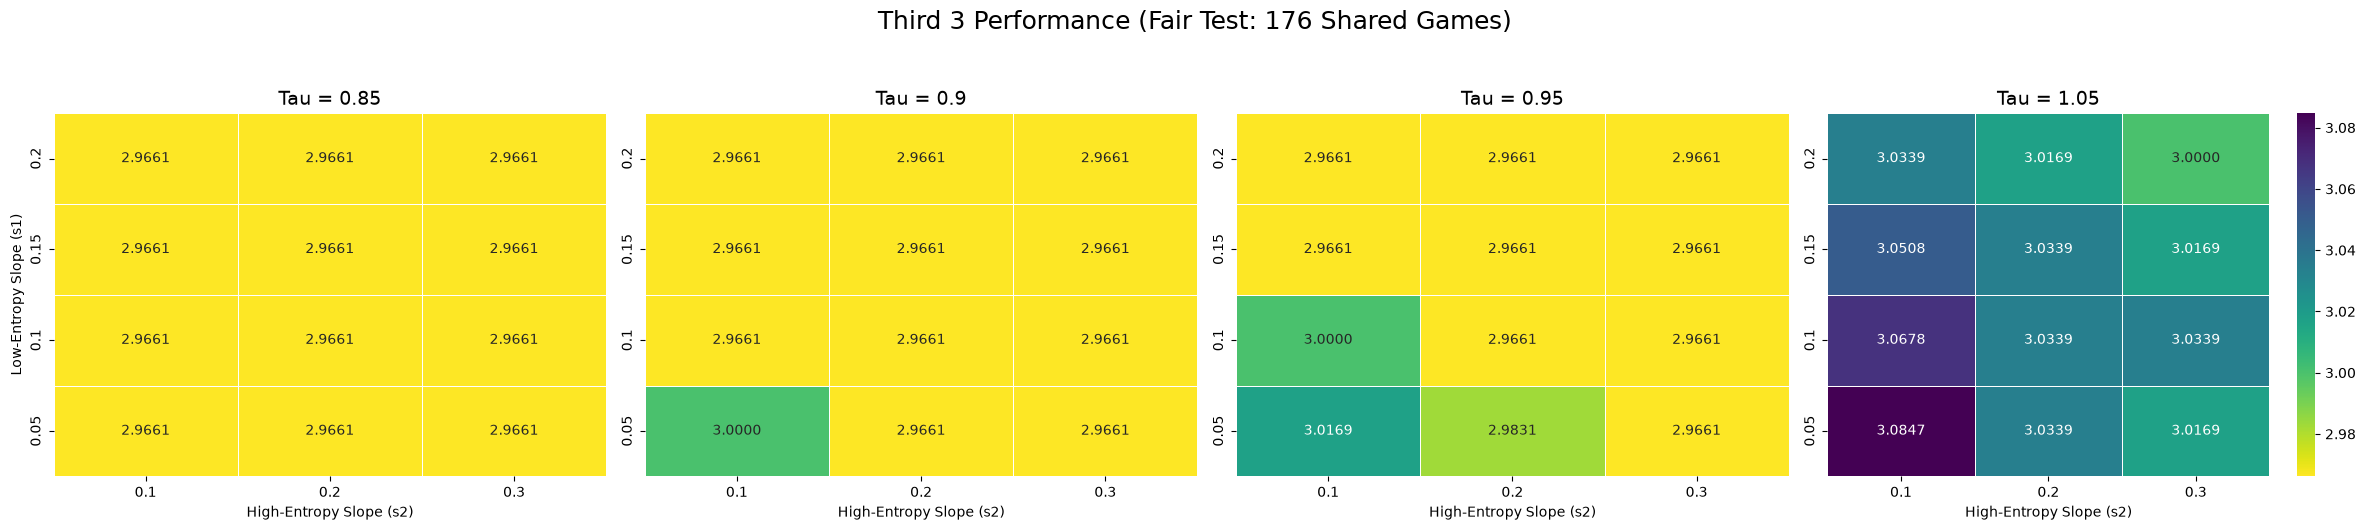

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import re

# Set up paths for the v2 grid search
DATA_DIR = Path("../data")
BOT9_DIR = DATA_DIR / "bot9_grid_search_v3"

# Game index splits
START_IDX = 1689
P1_END = START_IDX + 58
P2_END = P1_END + 59
P3_END = P2_END + 59

# 1. Load all dataframes and filter to the target date range
all_configs = []
for file_path in BOT9_DIR.glob("bot9_tau*_s1_*_s2_*.csv"):
    match = re.search(r"tau([\d\.]+)_s1_([\d\.]+)_s2_([\d\.]+)\.csv", file_path.name)
    if not match:
        continue
        
    tau, s1, s2 = map(float, match.groups())
    df = pd.read_csv(file_path)
    df_target = df[(df['game_num'] >= START_IDX) & (df['game_num'] <= P3_END)].copy()
    
    if not df_target.empty:
        all_configs.append({
            'tau': tau, 's1': s1, 's2': s2,
            'df': df_target,
            'games': set(df_target['game_num'])
        })

if not all_configs:
    print("No Bot 9 v2 data found for this range.")
else:
    # 2. Find the exact intersection of games across ALL configs for a 100% fair test
    common_games = all_configs[0]['games']
    for config in all_configs[1:]:
        common_games = common_games.intersection(config['games'])
        
    print(f"Fair comparison enforced: Evaluating {len(common_games)} identical games across all configurations.")

    # 3. Calculate averages using ONLY the intersected common games
    results = []
    for config in all_configs:
        df_fair = config['df'][config['df']['game_num'].isin(common_games)]
        
        t1 = df_fair[(df_fair['game_num'] >= START_IDX) & (df_fair['game_num'] <= P1_END)]['guess_count'].mean()
        t2 = df_fair[(df_fair['game_num'] > P1_END) & (df_fair['game_num'] <= P2_END)]['guess_count'].mean()
        t3 = df_fair[(df_fair['game_num'] > P2_END) & (df_fair['game_num'] <= P3_END)]['guess_count'].mean()
        overall = df_fair['guess_count'].mean()
        
        results.append({
            'tau': config['tau'], 's1': config['s1'], 's2': config['s2'],
            'Third 1': t1, 'Third 2': t2, 'Third 3': t3, 'Overall': overall
        })

    df_results = pd.DataFrame(results)
    
    # 4. Plot the gapless heatmaps
    df_results = df_results.sort_values(by=['tau', 's1', 's2'])
    unique_taus = sorted(df_results['tau'].unique())
    periods = ['Overall', 'Third 1', 'Third 2', 'Third 3']
    
    for period in periods:
        fig, axes = plt.subplots(1, len(unique_taus), figsize=(6 * len(unique_taus), 5))
        if len(unique_taus) == 1:
            axes = [axes]
            
        fig.suptitle(f"{period} Performance (Fair Test: {len(common_games)} Shared Games)", fontsize=18, y=1.05)
        
        vmin = df_results[period].min()
        vmax = df_results[period].max()
        
        for i, tau in enumerate(unique_taus):
            ax = axes[i]
            df_tau = df_results[df_results['tau'] == tau]
            
            pivot_df = df_tau.pivot(index='s1', columns='s2', values=period)
            
            sns.heatmap(
                pivot_df, 
                annot=True, 
                fmt=".4f", 
                cmap="viridis_r", 
                vmin=vmin, 
                vmax=vmax,
                cbar=(i == len(unique_taus) - 1),
                ax=ax,
                linewidths=.5
            )
            
            ax.set_title(f"Tau = {tau}", fontsize=14)
            ax.set_xlabel("High-Entropy Slope (s2)")
            ax.set_ylabel("Low-Entropy Slope (s1)" if i == 0 else "")
            ax.invert_yaxis()
            
        plt.tight_layout()
        plt.show()

In [19]:
import pandas as pd
from pathlib import Path
import re

# Set up paths for the v4 grid search
DATA_DIR = Path("../data")
BOT9_DIR = DATA_DIR / "bot9_grid_search_v4"

# Game index splits for the 177 games up to 28/7/26 (Game 1865)
START_IDX = 1689
P1_END = START_IDX + 58
P2_END = P1_END + 59
P3_END = P2_END + 59

# 1. Load all dataframes and filter to the target date range
all_configs = []
for file_path in BOT9_DIR.glob("bot9_tau*_s1_*_s2_*_s3_*.csv"):
    match = re.search(r"tau([\d\.]+)_s1_([\d\.]+)_s2_([\d\.]+)_s3_([\d\.]+)\.csv", file_path.name)
    if not match:
        continue
        
    tau, s1, s2, s3 = map(float, match.groups())
    df = pd.read_csv(file_path)
    df_target = df[(df['game_num'] >= START_IDX) & (df['game_num'] <= P3_END)].copy()
    
    if not df_target.empty:
        all_configs.append({
            'tau': tau, 's1': s1, 's2': s2, 's3': s3,
            'df': df_target,
            'games': set(df_target['game_num'])
        })

if not all_configs:
    print("No Bot 9 v4 data found in data/bot9_grid_search_v4.")
else:
    # 2. Find the exact intersection of games across ALL configs for a 100% fair test
    common_games = all_configs[0]['games']
    for config in all_configs[1:]:
        common_games = common_games.intersection(config['games'])
        
    print("================================================================================")
    print(f"FAIR TEST ANALYSIS (Evaluating {len(common_games)} shared games, Games {START_IDX}-{P3_END})")
    print("================================================================================\n")

    # 3. Calculate averages using ONLY the intersected common games
    results = []
    for config in all_configs:
        df_fair = config['df'][config['df']['game_num'].isin(common_games)]
        
        t1 = df_fair[(df_fair['game_num'] >= START_IDX) & (df_fair['game_num'] <= P1_END)]['guess_count'].mean()
        t2 = df_fair[(df_fair['game_num'] > P1_END) & (df_fair['game_num'] <= P2_END)]['guess_count'].mean()
        t3 = df_fair[(df_fair['game_num'] > P2_END) & (df_fair['game_num'] <= P3_END)]['guess_count'].mean()
        overall = df_fair['guess_count'].mean()
        
        results.append({
            'tau': config['tau'], 's1': config['s1'], 's2': config['s2'], 's3': config['s3'],
            'Third 1': t1, 'Third 2': t2, 'Third 3': t3, 'Overall': overall
        })

    df_res = pd.DataFrame(results)

    # 4. Print Top 10 for each period
    periods = [
        ('OVERALL PERFORMANCE', 'Overall', START_IDX, P3_END),
        ('THIRD 1 PERFORMANCE', 'Third 1', START_IDX, P1_END),
        ('THIRD 2 PERFORMANCE', 'Third 2', P1_END + 1, P2_END),
        ('THIRD 3 PERFORMANCE', 'Third 3', P2_END + 1, P3_END)
    ]

    for title, col_name, g_start, g_end in periods:
        print("================================================================================")
        print(f"TOP 10 LEADERBOARD: {title} (Games {g_start} to {g_end})")
        print("================================================================================")
        top10 = df_res.sort_values(col_name).head(10).reset_index(drop=True)
        print(top10.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
        print("\n")

FAIR TEST ANALYSIS (Evaluating 172 shared games, Games 1689-1865)

TOP 10 LEADERBOARD: OVERALL PERFORMANCE (Games 1689 to 1865)
   tau     s1     s2     s3  Third 1  Third 2  Third 3  Overall
0.9000 0.0500 0.1500 0.1000   3.1186   3.1964   2.9649   3.0930
0.9000 0.1000 0.1500 0.1000   3.1186   3.1964   2.9649   3.0930
0.9000 0.1000 0.1000 0.1000   3.1186   3.1964   2.9649   3.0930
0.9000 0.0500 0.2000 0.1000   3.1186   3.1964   2.9649   3.0930
0.9000 0.1500 0.1000 0.1000   3.1186   3.1964   2.9649   3.0930
0.9000 0.1500 0.1500 0.2000   3.1186   3.2143   2.9649   3.0988
0.9000 0.1500 0.1500 0.1000   3.1186   3.2143   2.9649   3.0988
0.9000 0.1500 0.2000 0.1500   3.1186   3.2143   2.9649   3.0988
1.0000 0.0500 0.2000 0.1500   3.1186   3.1964   2.9825   3.0988
1.0000 0.0500 0.2000 0.2000   3.1186   3.1964   2.9825   3.0988


TOP 10 LEADERBOARD: THIRD 1 PERFORMANCE (Games 1689 to 1747)
   tau     s1     s2     s3  Third 1  Third 2  Third 3  Overall
0.8000 0.0500 0.1000 0.1000   3.1186   3.

In [21]:
import pandas as pd
from pathlib import Path
import re

# Set up paths for the v4 grid search
DATA_DIR = Path("../data")
BOT9_DIR = DATA_DIR / "bot9_grid_search_v4"

# Define ranges:
# Range 1: All 245 repeat-era games (Game 1689 onwards)
START_IDX = 1689

# Range 2: From July 29, 2026 (Game 1866) to the present available files
CUTOFF_START_IDX = 1866

# 1. Load all available v4 configs
all_configs = []
for file_path in BOT9_DIR.glob("bot9_tau*_s1_*_s2_*_s3_*.csv"):
    match = re.search(r"tau([\d\.]+)_s1_([\d\.]+)_s2_([\d\.]+)_s3_([\d\.]+)\.csv", file_path.name)
    if not match:
        continue
        
    tau, s1, s2, s3 = map(float, match.groups())
    df = pd.read_csv(file_path)
    
    if not df.empty:
        all_configs.append({
            'tau': tau, 's1': s1, 's2': s2, 's3': s3,
            'df': df,
            'games': set(df['game_num'])
        })

if not all_configs:
    print("No Bot 9 v4 data found in data/bot9_grid_search_v4.")
else:
    # --- PART A: ALL REPEAT-ERA GAMES ---
    common_games_all = all_configs[0]['games']
    for config in all_configs[1:]:
        common_games_all = common_games_all.intersection(config['games'])
        
    results_all = []
    for config in all_configs:
        df_fair = config['df'][config['df']['game_num'].isin(common_games_all)]
        overall = df_fair['guess_count'].mean()
        results_all.append({
            'tau': config['tau'], 's1': config['s1'], 's2': config['s2'], 's3': config['s3'],
            'Overall (All Games)': overall
        })

    df_res_all = pd.DataFrame(results_all)

    print("================================================================================")
    print(f"TOP 10 LEADERBOARD: ALL REPEAT-ERA GAMES ({len(common_games_all)} shared games)")
    print("================================================================================")
    top10_all = df_res_all.sort_values('Overall (All Games)').head(10).reset_index(drop=True)
    print(top10_all.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
    print("\n")

    # --- PART B: GAMES FROM 29/7/26 TO PRESENT ---
    # Filter config dfs to only include games >= CUTOFF_START_IDX
    recent_configs = []
    for config in all_configs:
        df_recent = config['df'][config['df']['game_num'] >= CUTOFF_START_IDX].copy()
        if not df_recent.empty:
            recent_configs.append({
                'tau': config['tau'], 's1': config['s1'], 's2': config['s2'], 's3': config['s3'],
                'df': df_recent,
                'games': set(df_recent['game_num'])
            })
            
    if recent_configs:
        common_games_recent = recent_configs[0]['games']
        for config in recent_configs[1:]:
            common_games_recent = common_games_recent.intersection(config['games'])
            
        results_recent = []
        for config in recent_configs:
            df_fair = config['df'][config['df']['game_num'].isin(common_games_recent)]
            recent_avg = df_fair['guess_count'].mean()
            results_recent.append({
                'tau': config['tau'], 's1': config['s1'], 's2': config['s2'], 's3': config['s3'],
                'Overall (29/7/26 Onward)': recent_avg
            })

        df_res_recent = pd.DataFrame(results_recent)

        print("================================================================================")
        print(f"TOP 10 LEADERBOARD: FROM 29/7/26 ONWARD ({len(common_games_recent)} shared games)")
        print("================================================================================")
        top10_recent = df_res_recent.sort_values('Overall (29/7/26 Onward)').head(10).reset_index(drop=True)
        print(top10_recent.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
    else:
        print("No game records found from 29/7/26 onward.")

TOP 10 LEADERBOARD: ALL REPEAT-ERA GAMES (240 shared games)
   tau     s1     s2     s3  Overall (All Games)
0.9000 0.1500 0.1000 0.1000               3.0750
0.9000 0.1000 0.1000 0.1000               3.0750
0.9000 0.0500 0.1500 0.1000               3.0792
0.9000 0.1500 0.1500 0.2000               3.0792
0.9000 0.0500 0.2000 0.1000               3.0792
0.9000 0.1000 0.1500 0.1000               3.0792
0.9000 0.1500 0.2000 0.1000               3.0792
0.9000 0.1500 0.2000 0.1500               3.0792
0.9000 0.1500 0.1500 0.1000               3.0792
0.9000 0.1500 0.2000 0.2000               3.0792


TOP 10 LEADERBOARD: FROM 29/7/26 ONWARD (68 shared games)
   tau     s1     s2     s3  Overall (29/7/26 Onward)
0.9000 0.1500 0.1500 0.1000                    3.0294
0.9000 0.1500 0.1500 0.1500                    3.0294
0.9000 0.1500 0.1000 0.1000                    3.0294
0.9000 0.1500 0.1000 0.2000                    3.0294
0.9000 0.1500 0.2000 0.1500                    3.0294
0.9000 0.1500 0.2